# 01 · Bandits: explorar vs explotar
**Entornos:** Bandit · **Tiempo de ejecución:** ≤ 3 min en CPU · **Criterio de la lección:** UCB(c=1) rinde ≥ 1,25 por paso,
ε-greedy(0,1) ≥ 1,05 y le gana al greedy puro (límites inferiores de IC 95 %, n = 1000 problemas).

## 1. La idea en una frase
Con opciones cuyo valor no conocemos, hay que **gastar algunas jugadas en aprender** (explorar) sin dejar de **jugar lo mejor que sabemos** (explotar).

**En el sistema de Luca:** elegir qué carta inicial o qué línea de juego probar en la liga; la exploración de PPO (entropía) es el mismo dilema.
**En un problema de negocio:** elegir entre proveedores o rutas cuya calidad real se descubre usándolos.

## 2. La intuición y la fórmula
Cada brazo $a$ tiene una media desconocida $\mu_a$. Estimamos su valor con el promedio muestral, en forma incremental:

$$Q_{n+1}(a) = Q_n(a) + \frac{1}{N(a)}\bigl(r - Q_n(a)\bigr).$$

- **Greedy:** siempre $\arg\max_a Q(a)$. Se puede quedar pegado en un brazo mediocre que tuvo suerte al principio.
- **ε-greedy:** con probabilidad $\varepsilon$ un brazo al azar, si no el greedy.
- **UCB:** $\arg\max_a\; Q(a) + c\sqrt{\ln t / N(a)}$: optimismo ante la incertidumbre. Un brazo poco probado tiene bono grande;
  los no probados tienen prioridad máxima.

Medimos con el **arrepentimiento**: $\sum_t (\mu^* - \mu_{a_t})$, lo que se pierde por no jugar siempre el mejor brazo.

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
from rlf.core import EVAL_SEED_BASE, VecEnv, seed_everything
from rlf.eval.stats import mean_ci, paired_diff_ci, passes_lower
from rlf.envs.bandit import Bandit
TRAIN_SEED = int(os.environ.get("RLF_TRAIN_SEED", "0"))
seed_everything(TRAIN_SEED)
N_PROBLEMS = 1000      # 1000 problemas de bandit independientes, en paralelo sobre un VecEnv

## 3. El núcleo del algoritmo
Los tres algoritmos en una sola función, vectorizada sobre los 1000 problemas: `Q` y `N` tienen forma `[problemas, brazos]`.
El entorno es `Bandit` sobre `VecEnv`; el problema `b` usa la semilla de evaluación `EVAL_SEED_BASE + b`, así que todos los algoritmos
juegan **los mismos 1000 problemas** (evaluación pareada).

In [2]:
def run_bandit(algo, param, k=10, horizon=300, noise=1.0, n=N_PROBLEMS, seed=TRAIN_SEED):
    """algo ∈ {"random", "egreedy", "ucb"}; param = ε (egreedy) o c (ucb). Devuelve recompensas [horizon, n] y arrepentimiento por paso."""
    vec = VecEnv(lambda: Bandit(k=k, horizon=horizon, noise_std=noise), n,
                 seed_fn=lambda b, e: EVAL_SEED_BASE + e * n + b)
    vec.reset()
    rng = np.random.default_rng(seed)               # semilla de exploración del agente
    Q, N = np.zeros((n, k)), np.zeros((n, k))
    rows = np.arange(n)
    rewards = np.zeros((horizon, n)); regret = np.zeros((horizon, n))
    for t in range(1, horizon + 1):
        if algo == "random":
            a = rng.integers(0, k, n)
        else:
            if algo == "ucb":
                bonus = param * np.sqrt(np.log(t) / np.maximum(N, 1))
                score = np.where(N == 0, np.inf, Q + bonus)          # brazo no probado: prioridad máxima
            else:
                score = Q.copy()
            a = (score + rng.random((n, k)) * 1e-9).argmax(1)        # desempate al azar
            if algo == "egreedy":
                a = np.where(rng.random(n) < param, rng.integers(0, k, n), a)
        st = vec.step(a.astype(np.int64))                            # los índices de opción son los brazos
        r = st.rewards[:, 0]
        N[rows, a] += 1
        Q[rows, a] += (r - Q[rows, a]) / N[rows, a]                  # Q += (r - Q) / N
        rewards[t - 1] = r
        regret[t - 1] = [i["mu_best"] - i["mu_chosen"] for i in st.info]
    return rewards, regret

## 4. Entrenar y graficar la curva de aprendizaje
Seis agentes: aleatorio, greedy puro, ε-greedy con ε ∈ {0,01, 0,1} y UCB con c ∈ {1, 2}. Todos a 300 pasos sobre 1000 problemas
(300 000 pasos de entorno por agente).

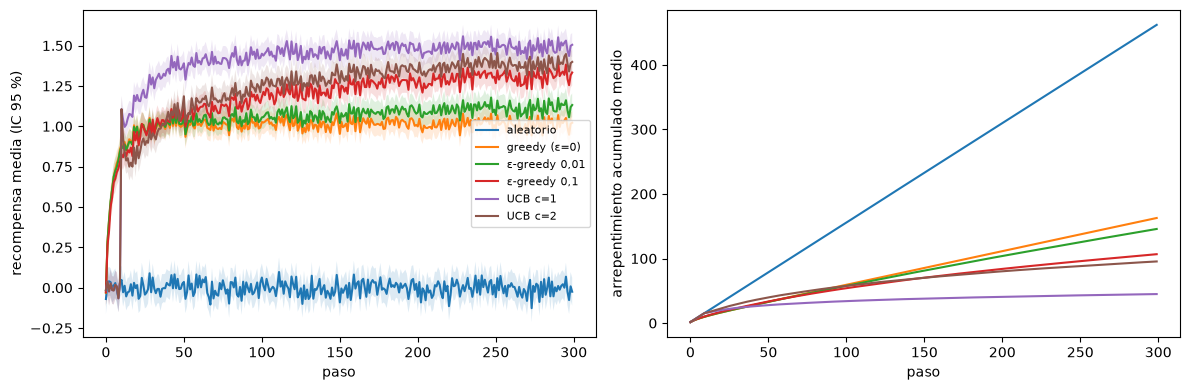

aleatorio       recompensa/paso -0.002  IC95 [-0.022,  0.017]   arrepentimiento  461.8
greedy (ε=0)    recompensa/paso  0.994  IC95 [ 0.958,  1.031]   arrepentimiento  162.8
ε-greedy 0,01   recompensa/paso  1.051  IC95 [ 1.015,  1.087]   arrepentimiento  145.8
ε-greedy 0,1    recompensa/paso  1.181  IC95 [ 1.148,  1.215]   arrepentimiento  106.7
UCB c=1         recompensa/paso  1.387  IC95 [ 1.350,  1.424]   arrepentimiento   44.9
UCB c=2         recompensa/paso  1.219  IC95 [ 1.182,  1.256]   arrepentimiento   95.4


In [3]:
ALGOS = {
    "aleatorio": ("random", 0), "greedy (ε=0)": ("egreedy", 0.0), "ε-greedy 0,01": ("egreedy", 0.01),
    "ε-greedy 0,1": ("egreedy", 0.1), "UCB c=1": ("ucb", 1.0), "UCB c=2": ("ucb", 2.0),
}
RES = {name: run_bandit(*spec) for name, spec in ALGOS.items()}
PER_PROBLEM = {name: rew.mean(0) for name, (rew, _) in RES.items()}     # recompensa media por paso de cada problema

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name, (rew, reg) in RES.items():
    curve = rew.mean(1); se = rew.std(1, ddof=1) / np.sqrt(N_PROBLEMS)
    axes[0].plot(curve, label=name); axes[0].fill_between(range(300), curve - 1.96 * se, curve + 1.96 * se, alpha=0.15)
    axes[1].plot(reg.mean(1).cumsum(), label=name)
axes[0].set_xlabel("paso"); axes[0].set_ylabel("recompensa media (IC 95 %)"); axes[0].legend(fontsize=8)
axes[1].set_xlabel("paso"); axes[1].set_ylabel("arrepentimiento acumulado medio")
plt.tight_layout(); plt.show()
for name, v in PER_PROBLEM.items():
    e = mean_ci(v); print(f"{name:15s} recompensa/paso {e.mean:6.3f}  IC95 [{e.lo:6.3f}, {e.hi:6.3f}]   arrepentimiento {RES[name][1].sum(0).mean():6.1f}")

## 5. Experimentos "predice antes de correr"
### Experimento 1 · ¿ε = 0 o ε = 0,1 gana a 300 pasos?
**Predice:** ¿explorar 10 % de las veces cuesta o ayuda? ¿Con qué diferencia, medida por problema?

In [4]:
d = paired_diff_ci(PER_PROBLEM["ε-greedy 0,1"], PER_PROBLEM["greedy (ε=0)"])
print(f"ε-greedy(0,1) − greedy: {d.mean:.3f}  IC95 [{d.lo:.3f}, {d.hi:.3f}]")
assert d.lo > 0 and d.n == 1000

ε-greedy(0,1) − greedy: 0.187  IC95 [0.157, 0.217]


<details><summary>Respuesta esperada</summary>

Explorar **ayuda**: ε-greedy(0,1) le gana al greedy puro por ≈ 0,19 por paso (IC ≈ [0,16; 0,22]) y el arrepentimiento baja de ≈ 163 a ≈ 107.
El greedy se queda pegado en el primer brazo que parece bueno; un poco de exploración lo rescata.
</details>

### Experimento 2 · ¿Qué constante `c` de UCB rinde más?
**Predice:** ¿c = 1 o c = 2? (más optimismo = más exploración).

In [5]:
d = paired_diff_ci(PER_PROBLEM["UCB c=1"], PER_PROBLEM["UCB c=2"])
print(f"UCB(c=1) − UCB(c=2): {d.mean:.3f}  IC95 [{d.lo:.3f}, {d.hi:.3f}]")
assert d.lo > 0

UCB(c=1) − UCB(c=2): 0.168  IC95 [0.164, 0.173]


<details><summary>Respuesta esperada</summary>

c = 1 rinde más (≈ +0,17 por paso frente a c = 2). Con recompensas de desviación 1 y solo 300 pasos, c = 2 explora de más: es demasiado
optimista y tarda en concentrarse. La constante correcta depende del ruido y del horizonte.
</details>

### Experimento 3 · ¿Cómo cambia el arrepentimiento con k = 10 vs k = 50?
**Predice:** ¿más brazos = más o menos arrepentimiento acumulado a 300 pasos? ¿Para UCB y para ε-greedy?

In [6]:
reg = {}
for k in (10, 50):
    for name in ("ε-greedy 0,1", "UCB c=1"):
        _, r = RES[name] if k == 10 else run_bandit(*ALGOS[name], k=50)
        reg[(name, k)] = r.sum(0).mean()
print({f"{n} k={k}": round(v, 1) for (n, k), v in reg.items()})
assert all(reg[(n, 50)] > reg[(n, 10)] for n in ("ε-greedy 0,1", "UCB c=1"))

{'ε-greedy 0,1 k=10': np.float64(106.7), 'UCB c=1 k=10': np.float64(44.9), 'ε-greedy 0,1 k=50': np.float64(259.9), 'UCB c=1 k=50': np.float64(203.7)}


<details><summary>Respuesta esperada</summary>

Sube en ambos: UCB pasa de ≈ 45 a ≈ 204 y ε-greedy de ≈ 107 a ≈ 260. Con 50 brazos hay que probar cada uno al menos una vez
(50 de los 300 pasos) y encontrar el mejor entre más candidatos cuesta más.
</details>

### Experimento 4 · ¿Y con más ruido (`noise_std = 3`)?
**Predice:** ¿sube o baja el arrepentimiento? ¿Sigue ganando UCB(c=1) a ε-greedy(0,1)?

In [7]:
noisy = {name: run_bandit(*ALGOS[name], noise=3.0)[1].sum(0).mean() for name in ("ε-greedy 0,1", "UCB c=1")}
base = {name: RES[name][1].sum(0).mean() for name in noisy}
print("ruido 1:", {n: round(v, 1) for n, v in base.items()}, " ruido 3:", {n: round(v, 1) for n, v in noisy.items()})
assert all(noisy[n] > base[n] for n in noisy) and noisy["UCB c=1"] < noisy["ε-greedy 0,1"]

ruido 1: {'ε-greedy 0,1': np.float64(106.7), 'UCB c=1': np.float64(44.9)}  ruido 3: {'ε-greedy 0,1': np.float64(166.9), 'UCB c=1': np.float64(126.3)}


<details><summary>Respuesta esperada</summary>

El arrepentimiento sube (UCB ≈ 45 → 126, ε-greedy ≈ 107 → 167): con ruido, cada estimación necesita más muestras para distinguir
brazos parecidos. UCB(c=1) sigue por debajo de ε-greedy, aunque la brecha se achica.
</details>

## 6. Criterio de la lección
n = 1000 problemas, `k = 10`, `horizon = 300`, semillas de evaluación.

In [8]:
rows = []
a = mean_ci(PER_PROBLEM["UCB c=1"]);            rows.append(("(a) UCB(c=1) recompensa/paso, LB ≥ 1,25", a, passes_lower(a, 1.25)))
b = mean_ci(PER_PROBLEM["ε-greedy 0,1"]);       rows.append(("(b) ε-greedy(0,1) recompensa/paso, LB ≥ 1,05", b, passes_lower(b, 1.05)))
c = paired_diff_ci(PER_PROBLEM["ε-greedy 0,1"], PER_PROBLEM["greedy (ε=0)"]); rows.append(("(c) ε-greedy(0,1) − greedy, LB > 0", c, passes_lower(c, 1e-12)))
r = mean_ci(PER_PROBLEM["aleatorio"]); se = PER_PROBLEM["aleatorio"].std(ddof=1) / np.sqrt(N_PROBLEMS)
rows.append(("(d) aleatorio compatible con 0 (|media| ≤ 3 EE)", r, abs(r.mean) <= 3 * se))
print(f"{'afirmación':52s} {'media':>7s} {'IC95':>18s}  ok")
for text, e, ok in rows:
    print(f"{text:52s} {e.mean:7.3f} [{e.lo:6.3f}, {e.hi:6.3f}]  {ok}")
assert all(ok for *_, ok in rows)

afirmación                                             media               IC95  ok
(a) UCB(c=1) recompensa/paso, LB ≥ 1,25                1.387 [ 1.350,  1.424]  True
(b) ε-greedy(0,1) recompensa/paso, LB ≥ 1,05           1.181 [ 1.148,  1.215]  True
(c) ε-greedy(0,1) − greedy, LB > 0                     0.187 [ 0.157,  0.217]  True
(d) aleatorio compatible con 0 (|media| ≤ 3 EE)       -0.002 [-0.022,  0.017]  True


## 7. Resumen y puente a la lección siguiente
- Explotar sin explorar se estanca; explorar de forma ciega (ε-greedy) ayuda; explorar con incertidumbre (UCB) ayuda más.
- Todo se comparó con los mismos 1000 problemas y con IC: sin eso, diferencias de 0,1 son invisibles.
- **Lección 2:** ¿cuántos episodios hacen falta para confiar en una comparación? Varianza, IC, evaluación pareada, Elo y sesgo de asiento.